# Week 2: Transaction categorizer

Goal: a model that reads a Description like `JOLLIBEE*4821` and predicts `Food & Drinks`.

**Part A** finishes Phase 1 (NumPy + merge). **Part B** is your first ML model.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/fake_transactions.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['Description'] = df['Description'].fillna('').str.strip()
expenses = df[df['Type'] == 'expense']
df.shape

(1410, 6)

---
# Part A: Finish Phase 1

## A1. NumPy
1. Turn the expense amounts into a NumPy array
2. Print the mean, median and standard deviation
3. How many expenses are over ₱1,000?

Hint: `expenses['Amount'].to_numpy()`, `np.mean()`, `np.median()`, `np.std()`. For 3, a comparison like `amounts > 1000` gives an array of True/False, and `.sum()` counts the Trues.

**Think:** why is the mean much bigger than the median?

In [2]:
# TODO
# 1. Convert expense amounts into a NumPy array
amounts = expenses['Amount'].to_numpy()

# 2. Calculate summary statistics
print(f"Mean: ₱{np.mean(amounts):,.2f}")
print(f"Median: ₱{np.median(amounts):,.2f}")
print(f"Standard deviation: ₱{np.std(amounts):,.2f}")

# 3. Count expenses over ₱1,000
print(f"Expenses over ₱1,000: {(amounts > 1000).sum()}")

Mean: ₱667.05
Median: ₱377.84
Standard deviation: ₱961.50
Expenses over ₱1,000: 207


## A2. Merge
Here's a monthly budget for some categories. Merge it with your **average monthly spending** per category, then add an `Over` column (spending minus budget).

Hint:
1. Number of months: `expenses['Date'].dt.to_period('M').nunique()`
2. Average per month: `groupby('Category')['Amount'].sum() / months`, then `.reset_index(name='AvgMonthly')`
3. `pd.merge(budgets, avg, on='Category')`

**Think:** which categories am I over budget on?

In [4]:
budgets = pd.DataFrame({
    'Category': ['Food & Drinks', 'Transportation', 'Groceries', 'Coffee & Snacks', 'Shopping'],
    'Budget':   [12000,           9000,             15000,       2500,              5000],
})

# TODO
# 1. Count the distinct months in your expense data
months = expenses['Date'].dt.to_period('M').nunique()

# 2. Calculate average monthly spending per category
avg = (
    expenses.groupby('Category')['Amount'].sum() / months
).reset_index(name='AvgMonthly')

# 3. Combine budgets and spending using matching category names
comparison = pd.merge(budgets, avg, on='Category')

# 4. Calculate spending minus budget
comparison['Over'] = comparison['AvgMonthly'] - comparison['Budget']

comparison

C:\Users\Ronmar abalos\AppData\Local\Temp\ipykernel_18636\2767529408.py:8: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  months = expenses['Date'].dt.to_period('M').nunique()


,Category,Budget,AvgMonthly,Over
0,Food & Drinks,12000,11970.099231,-29.900769
1,Transportation,9000,12935.106923,3935.106923
2,Groceries,15000,18464.631538,3464.631538
3,Coffee & Snacks,2500,2415.657692,-84.342308
4,Shopping,5000,12873.972308,7873.972308


---
# Part B: Your first ML model

## B1. Clean the text
Complete `clean_description` so all the Jollibee variants become `jollibee`:
1. Lowercase
2. Remove `*` and numbers. Hint: `re.sub(r'\*?\d+', '', text)`
3. Remove the branch names in `BRANCHES`. Hint: loop and `text.replace(b, '')`
4. Strip spaces at the ends

The `assert` lines check your function. If the cell runs with no error, it works.

In [11]:
BRANCHES = ['sm north', 'megamall', 'bgc', 'makati', 'qc', 'cubao', 'ortigas']

def clean_description(text):
    text = text.lower()
    text = re.sub(r'\*?\d+', '', text)

    for b in BRANCHES:
        text = text.replace(b, '')

    return text.strip()


assert clean_description('JOLLIBEE*4821') == 'jollibee'
assert clean_description('Jollibee Makati') == 'jollibee'
assert clean_description('  Starbucks ') == 'starbucks'

print('clean_description works!')

clean_description works!


Now build the training data: rows **with** a description, cleaned. `X` is the input (text), `y` is the answer (category).

In [12]:
data = df[df['Description'] != ''].copy()
data['Clean'] = data['Description'].apply(clean_description)
X, y = data['Clean'], data['Category']
data[['Description', 'Clean', 'Category']].sample(10, random_state=1)

,Description,Clean,Category
1176,Greenwich,greenwich,Food & Drinks
656,Tim Hortons Cubao,tim hortons,Coffee & Snacks
333,BUS FARE,bus fare,Transportation
583,LRT Makati,lrt,Transportation
106,foodpanda,foodpanda,Food & Drinks
929,Petron,petron,Transportation
548,Coffee Project,coffee project,Coffee & Snacks
63,maynilad,maynilad,Bills & Utilities
1166,MRTBEEPLOAD*2387,mrtbeepload,Transportation
314,Greenwich,greenwich,Food & Drinks


## B2. Split into train and test
The model learns from **train** (80%) and gets graded on **test** (20%), data it has never seen.

Hint: `from sklearn.model_selection import train_test_split`, then
`X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)`

**Think:** `stratify=y` keeps the same category mix in both parts. Why does that matter when Freelance / Client only has 8 rows?

In [13]:
# TODO

from sklearn.model_selection import train_test_split

# Clean descriptions and remove any that become blank
data = df.copy()
data['CleanDescription'] = data['Description'].apply(clean_description)
data = data[data['CleanDescription'] != '']

X = data['CleanDescription']  # Input: cleaned text
y = data['Category']          # Target: correct category

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"Training transactions: {len(X_train)}")
print(f"Test transactions: {len(X_test)}")

Training transactions: 1078
Test transactions: 270


## B3. Turn text into numbers (TF-IDF)
Models only understand numbers. TF-IDF scores pieces of text by how useful they are.

We use **character pieces** (`analyzer='char_wb', ngram_range=(2, 4)`), so `mcdonald's` and `mcdonalds` still look alike.

Hint: `from sklearn.feature_extraction.text import TfidfVectorizer`
- `vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4))`
- `X_train_vec = vec.fit_transform(X_train)` ← learn from train **only**
- `X_test_vec = vec.transform(X_test)` ← just apply to test

**Think:** why must you never `fit` on the test data? (Search: *data leakage*)

In [14]:
# TODO

from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(2, 4)
)

X_train_vec = vec.fit_transform(X_train)
X_test_vec = vec.transform(X_test)

print("Training shape:", X_train_vec.shape)
print("Test shape:", X_test_vec.shape)


Training shape: (1078, 1322)
Test shape: (270, 1322)


## B4. Train Logistic Regression
Hint: `from sklearn.linear_model import LogisticRegression`
- `model = LogisticRegression(max_iter=1000)`
- `model.fit(X_train_vec, y_train)`
- `accuracy_score(y_test, model.predict(X_test_vec))` from `sklearn.metrics`

In [18]:
# TODO
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Train the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

# Predict categories for the test transactions
y_pred = model.predict(X_test_vec)

# Compare predictions with the correct categories
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.1%}")

Test accuracy: 96.3%


## B5. Evaluate per category
Accuracy hides problems. Check each category.

Hint: from `sklearn.metrics`:
- `print(classification_report(y_test, predictions, zero_division=0))`
- `ConfusionMatrixDisplay.from_predictions(y_test, predictions, xticks_rotation='vertical')`

**Think:**
1. Which categories have the worst **recall**? Connect it to your Week 1 Q4 answer.
2. Where does the confusion matrix show mistakes? (Remember 7-Eleven is in two categories.)

                    precision    recall  f1-score   support

 Bills & Utilities       1.00      1.00      1.00        14
   Coffee & Snacks       0.91      1.00      0.95        41
     Entertainment       1.00      1.00      1.00         7
     Food & Drinks       0.93      1.00      0.97        86
Freelance / Client       0.00      0.00      0.00         2
         Groceries       1.00      0.88      0.94        25
        Healthcare       1.00      0.25      0.40         4
      Other Income       0.00      0.00      0.00         2
            Salary       1.00      1.00      1.00         5
          Shopping       1.00      1.00      1.00        14
    Transportation       1.00      1.00      1.00        70

          accuracy                           0.96       270
         macro avg       0.80      0.74      0.75       270
      weighted avg       0.95      0.96      0.95       270



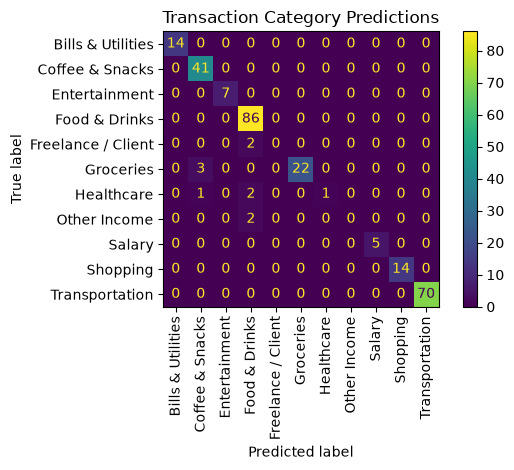

In [16]:
# TODO
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

predictions = model.predict(X_test_vec)

print(classification_report(
    y_test,
    predictions,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    xticks_rotation='vertical'
)
plt.title('Transaction Category Predictions')
plt.tight_layout()
plt.show()

**Challenge:** retrain with `LogisticRegression(max_iter=1000, class_weight='balanced')`. What happens to the small categories' recall? What happens to accuracy?

In [19]:
# TODO
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)
balanced_model.fit(X_train_vec, y_train)

balanced_predictions = balanced_model.predict(X_test_vec)

print(f"Original accuracy: {accuracy_score(y_test, predictions):.1%}")
print(f"Balanced accuracy: {accuracy_score(y_test, balanced_predictions):.1%}")

print(classification_report(
    y_test,
    balanced_predictions,
    zero_division=0
))

Original accuracy: 96.3%
Balanced accuracy: 98.9%
                    precision    recall  f1-score   support

 Bills & Utilities       1.00      1.00      1.00        14
   Coffee & Snacks       0.97      0.95      0.96        41
     Entertainment       1.00      1.00      1.00         7
     Food & Drinks       1.00      1.00      1.00        86
Freelance / Client       1.00      1.00      1.00         2
         Groceries       0.93      1.00      0.96        25
        Healthcare       1.00      0.75      0.86         4
      Other Income       1.00      1.00      1.00         2
            Salary       1.00      1.00      1.00         5
          Shopping       1.00      1.00      1.00        14
    Transportation       1.00      1.00      1.00        70

          accuracy                           0.99       270
         macro avg       0.99      0.97      0.98       270
      weighted avg       0.99      0.99      0.99       270



## B6. Compare with Decision Tree and Random Forest
Train both on the same `X_train_vec`. For each, print accuracy on **train** and on **test**.

Hint: `from sklearn.tree import DecisionTreeClassifier`, `from sklearn.ensemble import RandomForestClassifier`, use `random_state=42`. `model.score(X, y)` gives accuracy.

**Think:** a big gap between train and test accuracy is **overfitting**. Do you see one? Which model would you pick, and why? (Consider speed and size too, not just accuracy.)

In [20]:
# TODO
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    'Logistic Regression': model,
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

results = []

for name, classifier in models.items():
    classifier.fit(X_train_vec, y_train)

    train_accuracy = classifier.score(X_train_vec, y_train)
    test_accuracy = classifier.score(X_test_vec, y_test)

    results.append({
        'Model': name,
        'Train accuracy': train_accuracy,
        'Test accuracy': test_accuracy,
        'Gap': train_accuracy - test_accuracy
    })

results = pd.DataFrame(results).set_index('Model')
print(results.to_string(float_format=lambda value: f'{value:.1%}'))

                     Train accuracy  Test accuracy  Gap
Model                                                  
Logistic Regression           98.0%          96.3% 1.7%
Decision Tree                 98.8%          98.1% 0.6%
Random Forest                 98.8%          98.5% 0.3%


## B7. Cross-validation
One test split can be lucky or unlucky. Cross-validation tests on 5 different splits.

A **pipeline** bundles TF-IDF + model, so TF-IDF re-fits on each training fold (no leakage).

Hint: `from sklearn.pipeline import make_pipeline`, `from sklearn.model_selection import cross_val_score`
- `pipe = make_pipeline(TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4)), LogisticRegression(max_iter=1000))`
- `scores = cross_val_score(pipe, X, y, cv=5)` → print `scores.mean()` and `scores.std()`

In [21]:
# TODO
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

pipe = make_pipeline(
    TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4)),
    LogisticRegression(max_iter=1000)
)

scores = cross_val_score(pipe, X, y, cv=5)

print("Fold accuracies:", scores.round(3))
print(f"Mean accuracy: {scores.mean():.1%}")
print(f"Standard deviation: {scores.std():.1%}")

Fold accuracies: [0.963 0.959 0.974 0.978 0.952]
Mean accuracy: 96.5%
Standard deviation: 1.0%


## B8. Try it yourself
Train `pipe` on **all** the data (`pipe.fit(X, y)`), then predict new descriptions. Remember to clean them first!

Hint: `pipe.predict([clean_description(t) for t in ['GRAB*1234', 'puregold qc', 'Netflix']])`

Try tricky ones too. Can you find one it gets wrong?

In [22]:
# TODO
# Train the pipeline on all cleaned, nonblank training examples
pipe.fit(X, y)

# Try familiar merchants and ambiguous descriptions
new_descriptions = [
    'GRAB*1234',
    'puregold qc',
    'Netflix',
    '7-Eleven',
    'Grab Food',
    'UNKNOWN STORE'
]

cleaned = [clean_description(t) for t in new_descriptions]
predicted_categories = pipe.predict(cleaned)

for description, category in zip(new_descriptions, predicted_categories):
    print(f"{description:20} → {category}")

GRAB*1234            → Transportation
puregold qc          → Groceries
Netflix              → Bills & Utilities
7-Eleven             → Coffee & Snacks
Grab Food            → Food & Drinks
UNKNOWN STORE        → Shopping


## B9. Save the model
This file is what your FastAPI service will load in Week 3.

Hint: `import joblib`, `from pathlib import Path`
- `Path('../models').mkdir(exist_ok=True)`
- `joblib.dump(pipe, '../models/categorizer.joblib')`
- Check: `joblib.load('../models/categorizer.joblib').predict(['jollibee'])`

In [23]:
# TODO
import joblib
from pathlib import Path

# Create the models folder if it doesn't exist
Path('../models').mkdir(exist_ok=True)

# Save your trained pipeline
joblib.dump(pipe, '../models/categorizer.joblib')

print('Model saved!')

Model saved!


In [24]:
loaded_pipe = joblib.load('../models/categorizer.joblib')

prediction = loaded_pipe.predict(['jollibee'])
print(prediction)

['Food & Drinks']


In [25]:
print(Path('../models/categorizer.joblib').resolve())

D:\Web Projects\machine-learning\models\categorizer.joblib


In [26]:
loaded_pipe.predict([clean_description('JOLLIBEE*4821')])

array(['Food & Drinks'], dtype=object)

---
## Wrap-up
Write 3–5 sentences in this cell: what accuracy you got, which categories are weak and why, and which model you'd ship. (This becomes your blog post / README later.)

My Logistic Regression model achieved about 96.3% accuracy on the test set. 
The weakest categories were Freelance / Client and Other Income, both with 0% recall, and Healthcare, 
with 25% recall. These categories had few training examples, which likely made them harder to learn; 
ambiguous merchant descriptions can also cause mistakes. I would ship the TF-IDF and 
Logistic Regression pipeline as my first version because it performed well overall 
and is a practical choice for a fast, compact text classifier.

In [31]:
from sklearn.tree import DecisionTreeClassifier

shallow_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
shallow_tree.fit(X_train_vec, y_train)

print(f"Train accuracy: {shallow_tree.score(X_train_vec, y_train):.1%}")
print(f"Test accuracy: {shallow_tree.score(X_test_vec, y_test):.1%}")

Train accuracy: 46.8%
Test accuracy: 44.1%


Both scores are low because the shallow tree is too simple to learn the patterns across 11 categories, so it underfits and has **high bias**. Overfitting has **high variance**: the model learns the training data too closely, giving high training accuracy but much lower test accuracy.